# 1) Basics of using the `Wrapper` to compute solution type rates

In this notebook I will show the basics of using my `Wrapper`, and some of the basic features it contains

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

In [ ]:
import json
import sys

with open('./config.json', 'r', encoding='utf-8') as f:
    d = json.load(f)

sys.path.append(d["wrapper_path"])

import SimulateAstrometry, style, utils
from SimulateAstrometry import simulate_population_astrometry as simpopast

In [ ]:
parent_table = Table.read("./data/solar_mass_primaries.fits", format="fits")

this table contains all primaries around a solar mass within 200pc which have an xp spectrum, and therefore a derived mass

In [9]:
# this is (effectively) the minimum required table. I work with astropy tables, you better like it
# sky position + proper motions: ra, dec, pmra, pmdec. Proper motions do very little, so you can default them to 0. You still need to supply them
# distance (as parallax)
# apparent magnitude (as phot_g_mean_mag)
# primary mass (as mass)
# This table also has source_id, a colour and a metallicity. The code will ignore these
# But, the returned table will preserve them, and you can use any additional parameters 
# in any supplied functions. For example, you could make the period distribution depend on metallicity, or the mass distribution depend on colour.
parent_table[:5]

source_id,ra,dec,parallax,pmra,pmdec,phot_g_mean_mag,bp_rp,mh_single,mass
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
5478969249842164992,100.80327342731282,-61.93458816897337,5.055324217668468,-6.3423002704755405,4.530102690374626,12.510613,1.2859821,0.34141654,0.8998013
5479253370519160064,105.4834320298884,-61.01860612824198,5.158008652228242,-11.942845015350965,12.793031786566665,15.49515,2.9113073,0.34014013,0.8972822
5479299412568547072,105.11504138429784,-61.056461352999726,6.453046654986087,18.14847465201899,47.47206791693664,12.726457,1.6481705,0.33151603,0.88025504
5479383490848343936,107.71844787388191,-60.3907311253187,5.072678624137714,-10.166087092891827,-17.35885986815572,12.623677,1.1938934,0.4026421,0.8444216
5479504437127465088,104.1816749781279,-60.68798458877736,18.77176130288381,3.2788501354270636,-224.11595795586692,9.754526,1.1603775,0.08066037,0.8047467


## A simple example
Simulate an example population. These are the default parameter distributions
- log-normal period distribution peaking at 5 with a spread of 3
- uniform mass ratio distribution with a minimum of 0.1
- thermal eccentricities
- flux ratios set by a simple mass-luminosity relationship

In [ ]:
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5, # sample 5000 objects from the supplied catalogue, with a binary fraction of 50%
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, # the all-in-one pipeline from DR3 adapted from Gaiamock
                                        period_model=utils.normal_distribution, period_kwargs={"gaussian_params":(5, 3), "lims":(1, 8), "log":True}, # log-normal Moe+DiStefano 2017
                                        companion_mass_model=utils.uniform_distribution, m_kwargs={"lims": [0.1, 1]}, # flat mass ratio distribution between 0.1 and 1
                                        eccentricity_model=utils.power_law_distribution, ecc_kwargs={"index": 1, "lims": [0, 0.99]}, # thermal eccentricity distribution (which is just a power law)
                                        flux_ratio_model=utils.flux_ratio_power_law, f_kwargs={"index": 4}, # mass-luminosity relationship M~L^4
                                                                            
                                        return_fits=True, return_statistics=True, n_jobs=5) # n_jobs can be set to -1 for optimal efficiency, but your laptop will COOK. Do it.

In [ ]:
utils.postproces_solution_type(objs, astrometry_results)
processed_res = utils.postprocess_fits(astrometry_results)

/home/bepennell/research/GaiamockWrapper/.wrapperenv/lib/python3.10/site-packages/numpy/_core/numeric.py:353: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(a, fill_value, casting='unsafe')


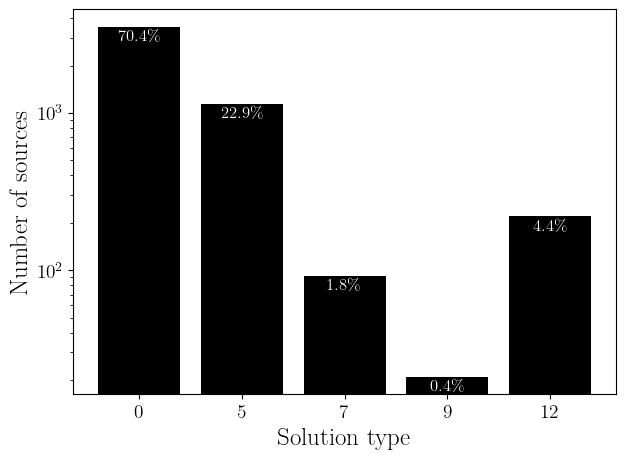

In [ ]:
soltypes = [0,5,7,9,12]
counts, bins, _ = plt.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
plt.xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
plt.xlabel("Solution type")
plt.ylabel("Number of sources")
plt.yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        plt.text(i, count * 0.78, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

plt.show()

## Changing the distances of the parent sample
By default we would follow the parent sample, which in this case is between 50 and 200pc. But we can decide to readjust to, say, 200-500pc.
This is sampled assuming the sources are isotropically distrbuted (and therefore $P(d) \propto d^2$), and the magnitude of the sources are automatically corrected based on this distance. So far, no dust models are used. You'd have to do ts yourself

This contains the same distribution of parameters as before, the only change is the distances.

In [ ]:
objs, astrometry_results = simpopast(object_count=2500, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        reassign_parallaxes=True, plx_kwargs={"dist_range": (200, 500)}, # set the distance to be 200-500 pc
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to 1250 sources...
(2) Computing astrometry for 2500 sources...


Computing astrometry for all sources...:   0%|          | 0/2500 [00:00<?, ?it/s]

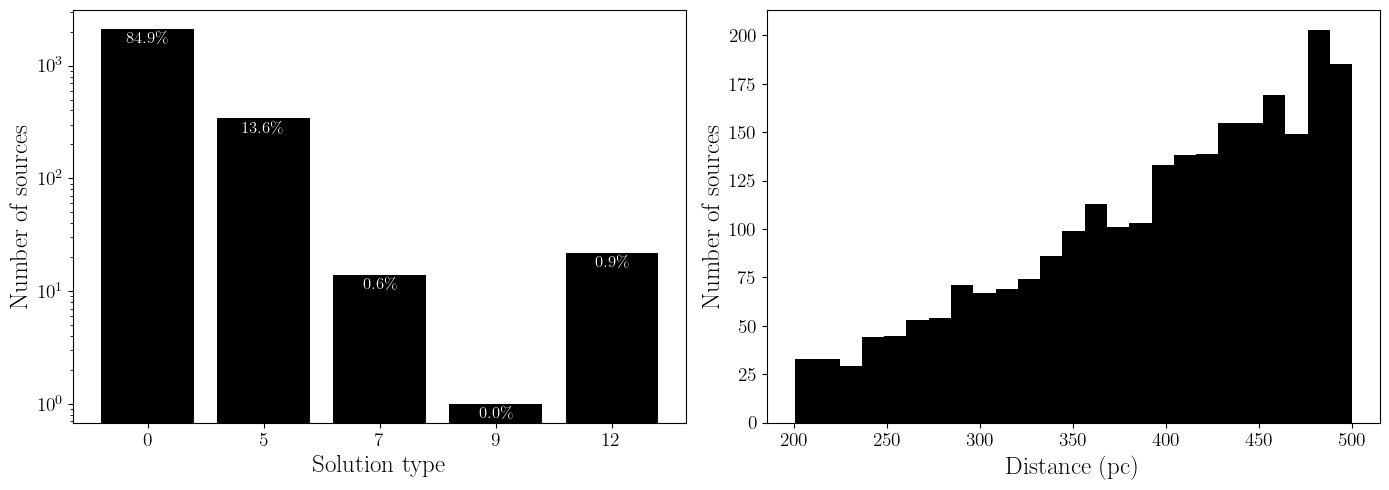

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
soltypes = [0,5,7,9,12]
utils.postproces_solution_type(objs, astrometry_results)
counts, bins, _ = ax.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
ax.set_xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
ax.set_xlabel("Solution type")
ax.set_ylabel("Number of sources")
ax.set_yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        ax.text(i, count * 0.7, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

ax = axs[1]
ax.hist(1000/objs["parallax"], bins=25)
ax.set_xlabel("Distance (pc)")
ax.set_ylabel("Number of sources")

plt.tight_layout()
plt.show()

and we can see that the higher order solutions become less common as we've moved further away compared to the last example, as we expect.

## Sampling on companion mass instead
By default we sample mass ratios, but you can do companion mass instead

In [ ]:
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        companion_mass_model=utils.uniform_distribution, m_kwargs={"lims": [0.2, 0.65]}, # let's make the companions just m stars :)
                                        compute_mass_ratios=False, # tell it that we aren't sampling mass ratios, but rather companion masses directly
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to 2500 sources...
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

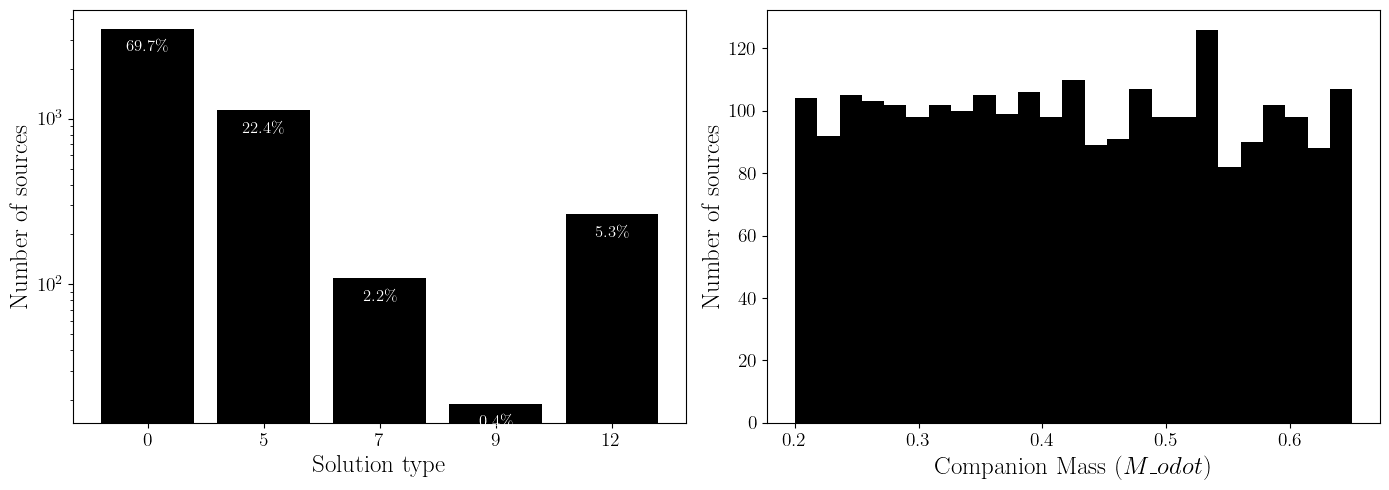

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
soltypes = [0,5,7,9,12]
utils.postproces_solution_type(objs, astrometry_results)
counts, bins, _ = ax.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
ax.set_xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
ax.set_xlabel("Solution type")
ax.set_ylabel("Number of sources")
ax.set_yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        ax.text(i, count * 0.7, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

ax = axs[1]
ax.hist(objs["m2"], bins=25)
ax.set_xlabel(r"Companion Mass ($M\_odot$)")
ax.set_ylabel("Number of sources")

plt.tight_layout()
plt.show()

## Supplying a mass-dependant multiplicity
By default we use a flat binary fraction, but you can supply your own

In [ ]:
def multiplicity_on_mass(table, rate_lims=(0.2, 0.5), mass_lims=(0.8, 1.2)):
    """
    Create a linearly increasing multiplicity as a function of primary mass
    """
    
    masses = np.clip(table["mass"], mass_lims[0], mass_lims[1])
    return np.interp(masses, [mass_lims[0], mass_lims[1]], [rate_lims[0], rate_lims[1]])

In [ ]:
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=multiplicity_on_mass,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to sources based on binary fraction function...
(1) Assigned 1646 binaries, for an overall binary fraction of 32.920000\%
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

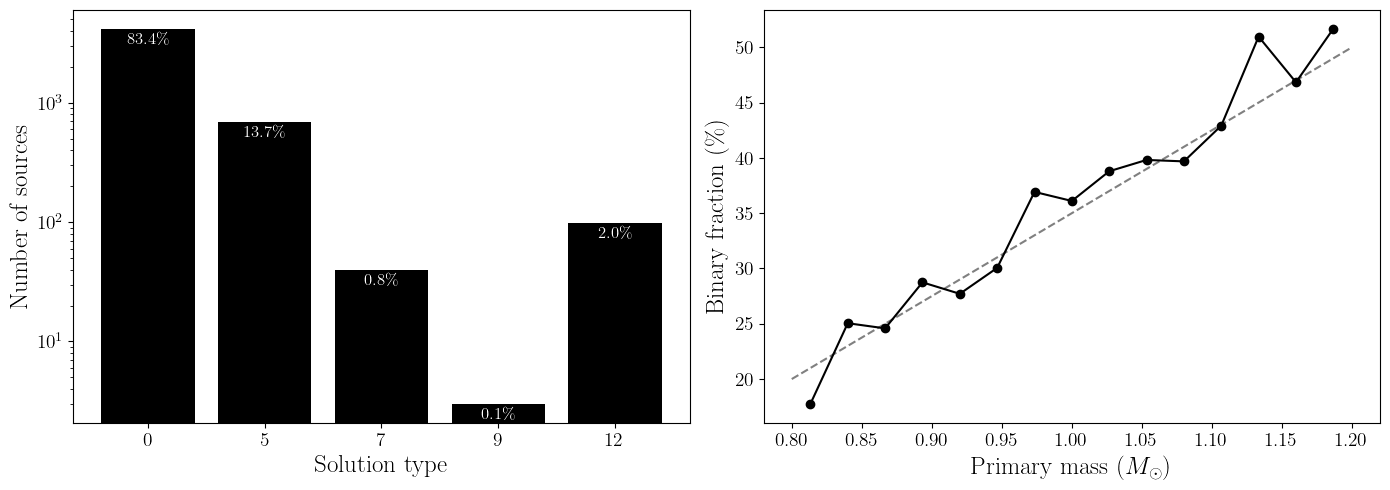

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
soltypes = [0,5,7,9,12]
utils.postproces_solution_type(objs, astrometry_results)
counts, bins, _ = ax.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
ax.set_xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
ax.set_xlabel("Solution type")
ax.set_ylabel("Number of sources")
ax.set_yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        ax.text(i, count * 0.7, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

ax = axs[1]
nbins = 15
mass_bins = np.linspace(0.8, 1.2, nbins+1)
rates = np.zeros(nbins)
for i in range(nbins):
    mask = (objs["mass"] >= mass_bins[i]) & (objs["mass"] < mass_bins[i+1])
    if np.sum(mask) > 0:
        rates[i] = np.sum(objs["is_binary"][mask]) / np.sum(mask) * 100
ax.plot(0.5 * (mass_bins[:-1] + mass_bins[1:]), rates, marker="o", linestyle="-")
ax.plot([0.8, 1.2], [20, 50], linestyle="--", color="gray", zorder=0)
ax.set_xlabel(r"Primary mass ($M_\odot$)")
ax.set_ylabel("Binary fraction (\%)")

plt.tight_layout()
plt.show()

## And using the DR4 "BH3 cuts" pipeline

The DR4 pipeline generally takes far longer because the operating scheme is to fit everything with an orbit solution. Maybe like ~minute per 1000 sources. This defaults to not using gaiamock mod, and I would encourage not using it.

In [ ]:
objs_dr4, astrometry_results_dr4 = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr4_astrometric_pipeline, 
                                        return_fits=True, return_statistics=True, n_jobs=5)
utils.postproces_solution_type(objs_dr4, astrometry_results_dr4)

(1) Assigning companions to 2500 sources...
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

In [ ]:
# make a DR3 set for comparison
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5, # sample 5000 objects from the supplied catalogue, with a binary fraction of 50%
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, # the all-in-one pipeline from DR3 adapted from Gaiamock
                                        return_fits=True, return_statistics=True, n_jobs=5) # n_jobs can be set to -1 for optimal efficiency, but your laptop will COOK. Do it.
utils.postproces_solution_type(objs, astrometry_results)

(1) Assigning companions to 2500 sources...
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

/home/bepennell/research/GaiamockWrapper/.wrapperenv/lib/python3.10/site-packages/numpy/_core/numeric.py:353: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(a, fill_value, casting='unsafe')


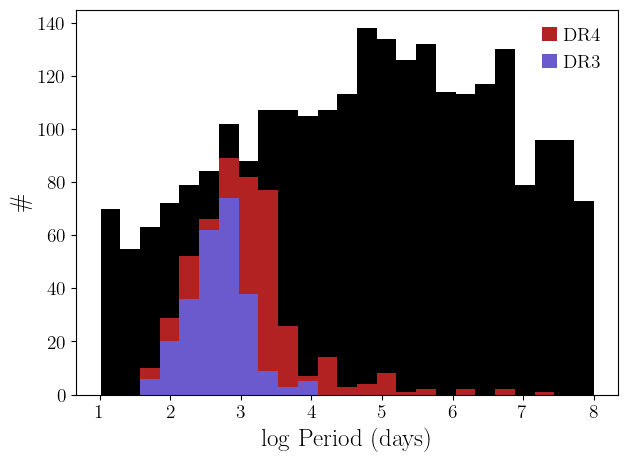

In [9]:
tbins = plt.hist(np.log10(objs_dr4["period"]), bins=25)
plt.hist(np.log10(objs_dr4["period"][objs_dr4["solution_type"] == 12]), bins=tbins[1], label="DR4")
plt.hist(np.log10(objs["period"][objs["solution_type"] == 12]), bins=tbins[1], label="DR3")
plt.legend()
plt.xlabel(r"$\log$ Period (days)")
plt.ylabel("\#")
plt.show()

You can see how the baseline icnreases the number of high period companions, and the less restrictive cuts allowing for more companions in general.
I think more realistic data will prevent these super high period companions, but maybe not idk